In [2]:

!pip install opencv-python numpy matplotlib scikit-image -q


In [3]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
import os

from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:

# Upload Underwater Image

uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("Please upload an image!")

image_name = list(uploaded.keys())[0]

image_data = np.frombuffer(
    uploaded[image_name],
    np.uint8
)

original_image = cv2.imdecode(
    image_data,
    cv2.IMREAD_COLOR
)

if original_image is None:
    raise ValueError("Image could not be loaded!")

print("Image uploaded successfully!")
print("Image Name:", image_name)
print("Image Dimensions:", original_image.shape)


Saving underwater.jpg to underwater.jpg
Image uploaded successfully!
Image Name: underwater.jpg
Image Dimensions: (1667, 2500, 3)


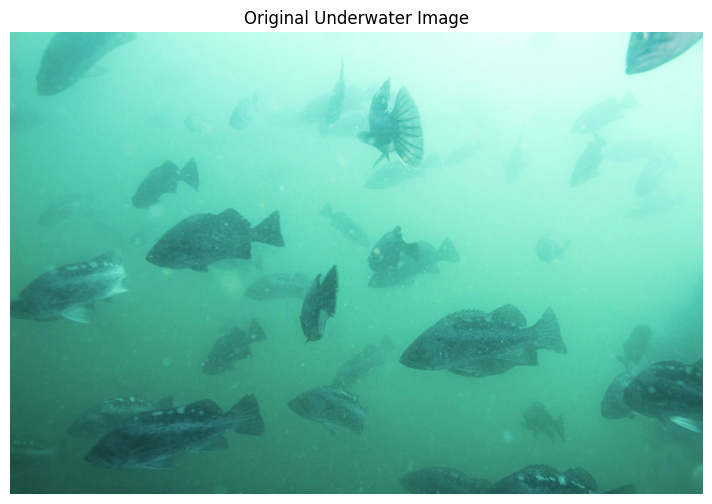

Original image displayed successfully!


In [5]:

# Convert BGR to RGB
original_rgb = cv2.cvtColor(
    original_image,
    cv2.COLOR_BGR2RGB
)

# Display Original Image
plt.figure(figsize=(10, 6))

plt.imshow(original_rgb)
plt.title("Original Underwater Image")
plt.axis("off")

plt.show()

print("Original image displayed successfully!")


In [6]:

def color_correction(image):

    # Convert image to float
    image = image.astype(np.float32)

    # Calculate average of each colour channel
    avg_b = np.mean(image[:, :, 0])
    avg_g = np.mean(image[:, :, 1])
    avg_r = np.mean(image[:, :, 2])

    # Calculate average brightness
    avg = (avg_b + avg_g + avg_r) / 3

    # Correct colour distortion
    image[:, :, 0] *= avg / (avg_b + 1e-6)
    image[:, :, 1] *= avg / (avg_g + 1e-6)
    image[:, :, 2] *= avg / (avg_r + 1e-6)

    # Keep pixel values between 0 and 255
    image = np.clip(image, 0, 255)

    return image.astype(np.uint8)


print("Colour correction function created successfully!")


Colour correction function created successfully!


In [7]:

# Apply colour correction

color_corrected = color_correction(original_image)

print("Colour correction completed!")


Colour correction completed!


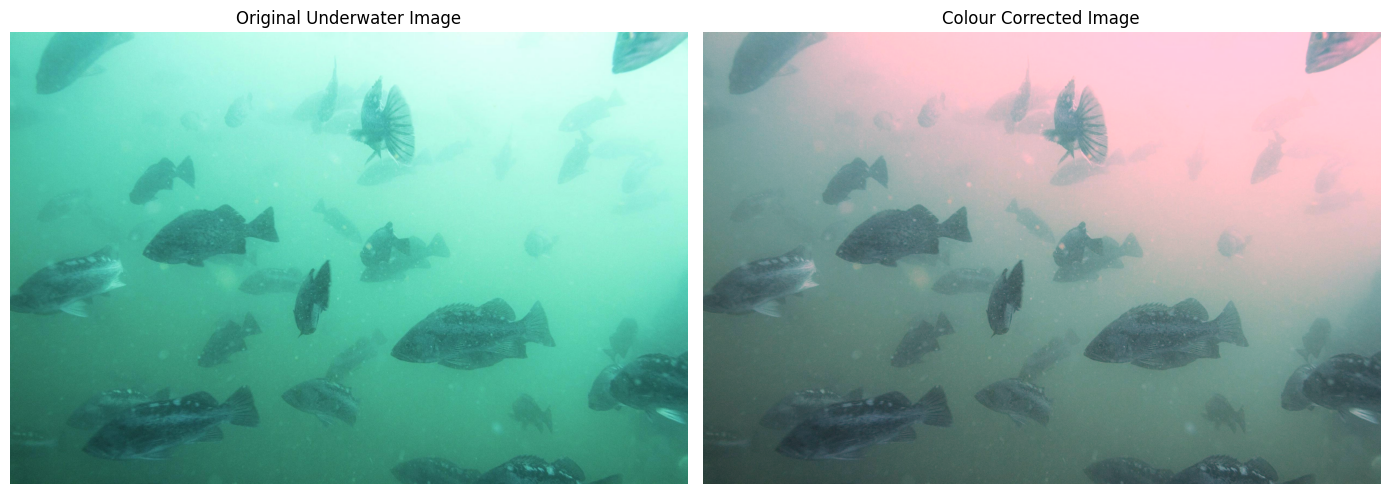

In [8]:

# Convert BGR to RGB

original_rgb = cv2.cvtColor(
    original_image, cv2.COLOR_BGR2RGB
)

corrected_rgb = cv2.cvtColor(
    color_corrected, cv2.COLOR_BGR2RGB
)

# Display comparison

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Underwater Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(corrected_rgb)
plt.title("Colour Corrected Image")
plt.axis("off")

plt.tight_layout()
plt.show()


In [9]:

def dark_channel(image, size=15):

    # Find minimum value of colour channels
    min_channel = np.min(image, axis=2)

    # Create rectangular kernel
    kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT,
        (size, size)
    )

    # Apply erosion
    dark = cv2.erode(min_channel, kernel)

    return dark


print("Dark Channel function created successfully!")


Dark Channel function created successfully!


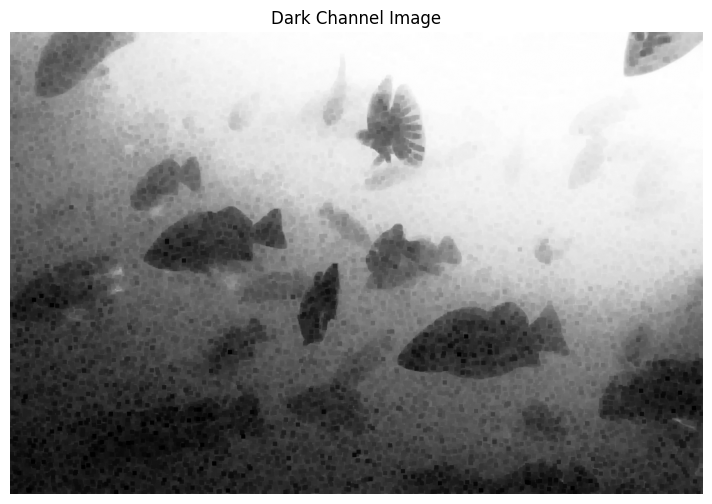

Dark Channel generated successfully!


In [10]:

# Generate Dark Channel

dark = dark_channel(color_corrected)

# Display Dark Channel Image
plt.figure(figsize=(10, 6))

plt.imshow(dark, cmap="gray")
plt.title("Dark Channel Image")
plt.axis("off")

plt.show()

print("Dark Channel generated successfully!")


In [11]:

def remove_haze(image):

    img = image.astype(np.float32) / 255.0

    # Calculate dark channel
    dark = dark_channel(img)

    # Estimate atmospheric light
    flat_dark = dark.reshape(-1)
    flat_img = img.reshape(-1, 3)

    number = max(1, int(len(flat_dark) * 0.001))

    indices = np.argpartition(
        flat_dark, -number
    )[-number:]

    atmospheric_light = np.max(
        flat_img[indices], axis=0
    )

    # Estimate transmission
    normalized = img / (atmospheric_light + 1e-6)

    transmission = 1 - 0.85 * dark_channel(normalized)

    # Smooth transmission
    transmission = cv2.bilateralFilter(
        transmission.astype(np.float32),
        9, 0.1, 7
    )

    # Recover image
    transmission = np.maximum(transmission, 0.25)

    restored = (
        img - atmospheric_light
    ) / transmission[:, :, None] + atmospheric_light

    restored = np.clip(restored, 0, 1)

    return (restored * 255).astype(np.uint8)


print("Haze removal function created successfully!")


Haze removal function created successfully!


In [12]:

# Apply haze removal

dehazed_image = remove_haze(color_corrected)

print("Underwater haze removal completed!")


Underwater haze removal completed!


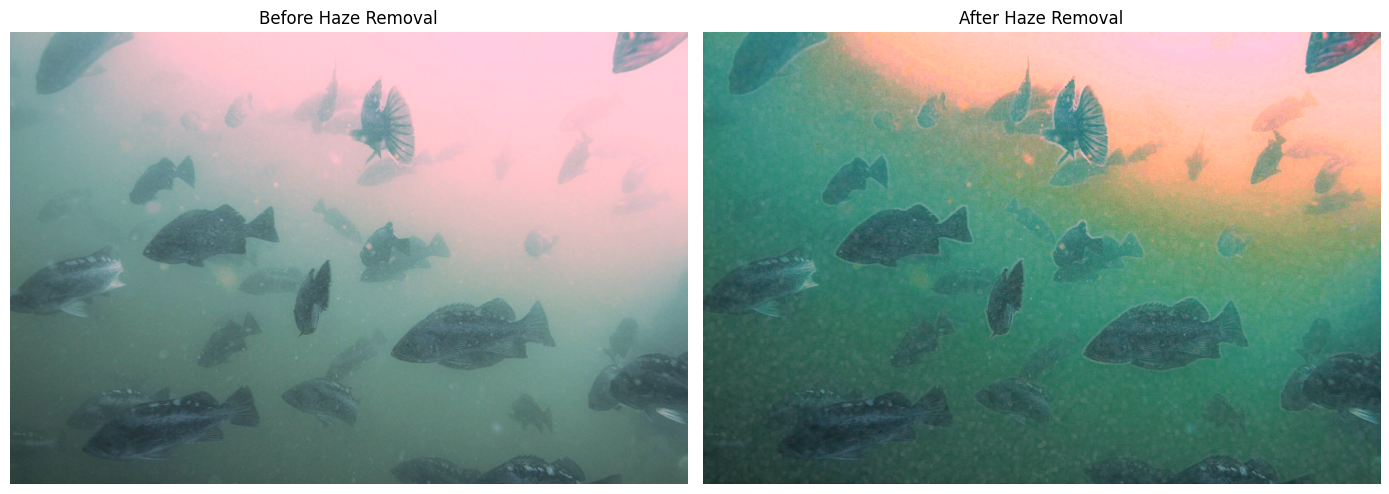

In [13]:

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(
    color_corrected, cv2.COLOR_BGR2RGB
))
plt.title("Before Haze Removal")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(
    dehazed_image, cv2.COLOR_BGR2RGB
))
plt.title("After Haze Removal")
plt.axis("off")

plt.tight_layout()
plt.show()


In [14]:

def enhance_contrast(image):

    # Convert BGR to LAB colour space
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)

    # Split LAB channels
    l, a, b = cv2.split(lab)

    # Apply CLAHE
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l)

    # Merge channels
    enhanced_lab = cv2.merge((enhanced_l, a, b))

    # Convert LAB back to BGR
    enhanced_image = cv2.cvtColor(
        enhanced_lab,
        cv2.COLOR_LAB2BGR
    )

    return enhanced_image


print("Contrast enhancement function created successfully!")


Contrast enhancement function created successfully!


In [15]:

# Apply contrast enhancement

contrast_image = enhance_contrast(dehazed_image)

print("Contrast enhancement completed!")


Contrast enhancement completed!


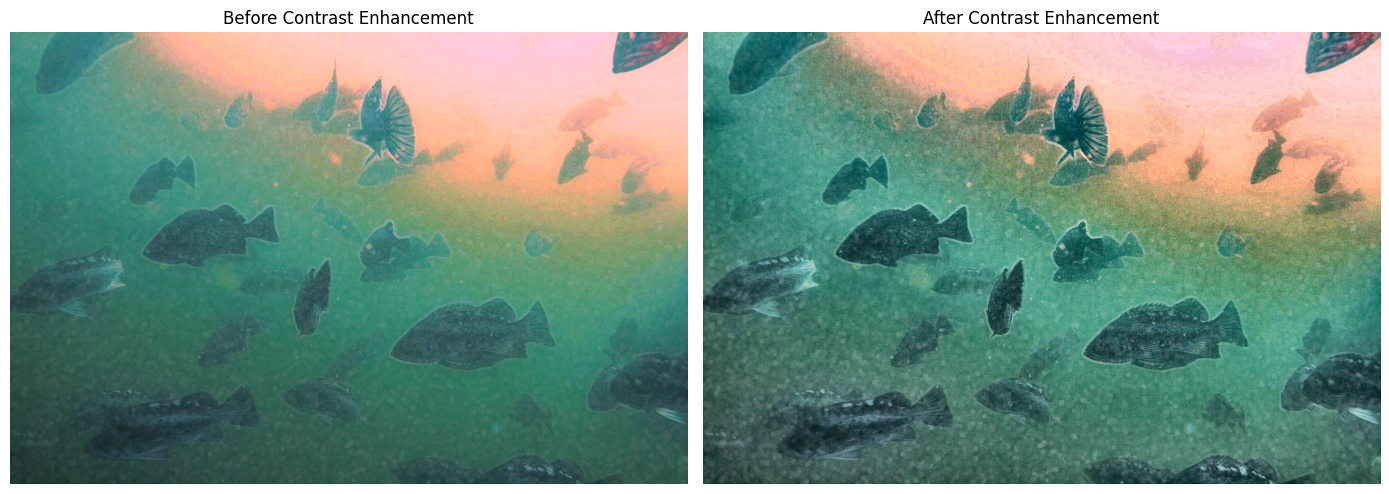

In [16]:

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(
    dehazed_image, cv2.COLOR_BGR2RGB
))
plt.title("Before Contrast Enhancement")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(
    contrast_image, cv2.COLOR_BGR2RGB
))
plt.title("After Contrast Enhancement")
plt.axis("off")

plt.tight_layout()
plt.show()


In [17]:

def sharpen_image(image):

    # Create blurred image
    blurred = cv2.GaussianBlur(
        image, (0, 0), 2
    )

    # Apply sharpening
    sharpened = cv2.addWeighted(
        image, 1.5,
        blurred, -0.5,
        0
    )

    return sharpened


print("Image sharpening function created successfully!")


Image sharpening function created successfully!


In [18]:

# Apply image sharpening

final_image = sharpen_image(contrast_image)

print("Image sharpening completed!")


Image sharpening completed!


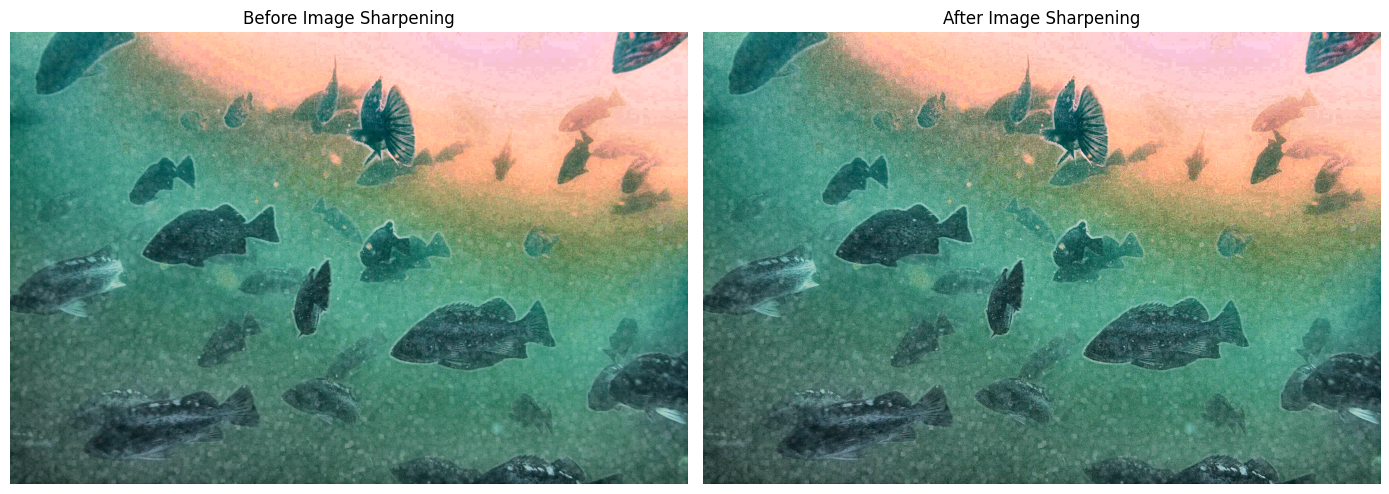

In [19]:

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(
    contrast_image, cv2.COLOR_BGR2RGB
))
plt.title("Before Image Sharpening")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(
    final_image, cv2.COLOR_BGR2RGB
))
plt.title("After Image Sharpening")
plt.axis("off")

plt.tight_layout()
plt.show()


In [20]:

# Calculate PSNR
psnr_value = peak_signal_noise_ratio(
    original_image,
    final_image,
    data_range=255
)

# Calculate SSIM
ssim_value = structural_similarity(
    original_image,
    final_image,
    channel_axis=2,
    data_range=255
)

print("Image Quality Evaluation Results")
print("--------------------------------")
print("PSNR:", round(psnr_value, 2), "dB")
print("SSIM:", round(ssim_value, 4))


Image Quality Evaluation Results
--------------------------------
PSNR: 13.22 dB
SSIM: 0.4703


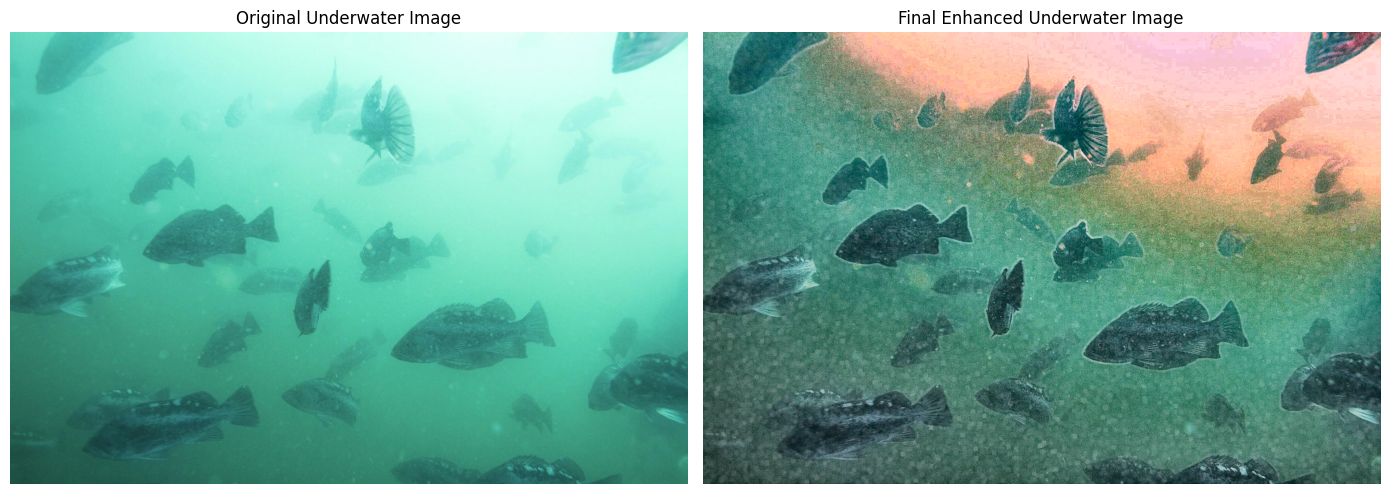

Final Image Comparison Completed!


In [21]:

# Convert BGR to RGB

original_rgb = cv2.cvtColor(
    original_image,
    cv2.COLOR_BGR2RGB
)

final_rgb = cv2.cvtColor(
    final_image,
    cv2.COLOR_BGR2RGB
)

# Display comparison

plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Underwater Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(final_rgb)
plt.title("Final Enhanced Underwater Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Final Image Comparison Completed!")


Final image saved successfully!


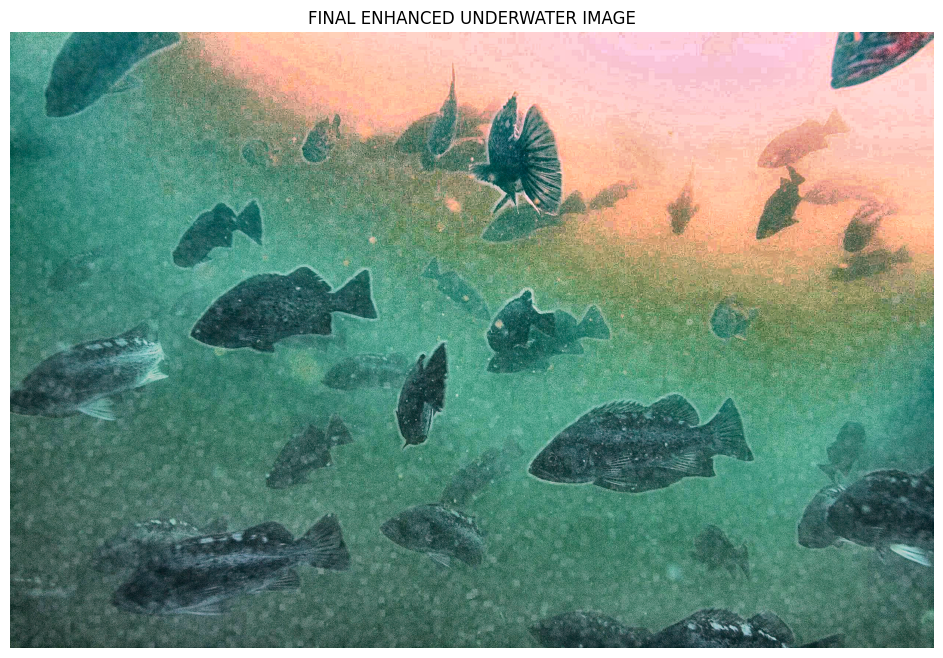

Final Enhanced Image Displayed Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:

# Save final enhanced image

output_name = "Enhanced_Underwater_Image.jpg"

cv2.imwrite(output_name, final_image)

print("Final image saved successfully!")

# Display final enhanced image below

final_rgb = cv2.cvtColor(
    final_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 8))

plt.imshow(final_rgb)
plt.title("FINAL ENHANCED UNDERWATER IMAGE")
plt.axis("off")

plt.show()

print("Final Enhanced Image Displayed Successfully!")

# Download final image

files.download(output_name)

